In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.model_selection import train_test_split

In [2]:
#Load data
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data =  pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')

In [3]:
Data

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,10328,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,...,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10329,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,...,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,10330,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,...,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,10331,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,...,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [4]:
Data = Data.iloc[:, 1:]

In [5]:
Data["Labels"] = Data["FPS"].apply(lambda x: 0 if x >= 60 else 1)

In [6]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,...,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll,Labels
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,...,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71,0
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,...,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73,0
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,...,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75,0
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,...,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85,0
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,...,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,...,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87,1
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,...,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15,1
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,...,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37,1
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,...,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80,1


In [7]:
# Separate features (X) and target (y)
X = Data.drop('Labels', axis = 1)

In [8]:
y = Data['Labels']

In [9]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [10]:
 # Apply Variance Threshold method
vt = VarianceThreshold(threshold=0.1)
X_vt = vt.fit_transform(X)

In [11]:
# Use SelectKBest to choose the top k features
k = 5   # Specify the number of top features you want to select
skb = SelectKBest(f_classif, k=k)
X_skb = skb.fit_transform(X_vt, y)

In [12]:
# Create a new DataFrame with the selected features
selected_features = X.columns[vt.get_support()][skb.get_support()]
selected_data = pd.DataFrame(X_skb, columns=selected_features)

In [13]:
selected_data

,FPS,Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),avgMtpLatency
0,62.06,0.00,16.11,16.11,0.00
1,68.85,0.00,16.11,14.92,10.89
2,76.57,0.00,16.11,13.61,10.89
3,79.07,0.00,16.11,12.95,21.02
4,69.74,0.00,16.11,13.88,16.53
...,...,...,...,...,...
10327,36.55,27.36,115.83,67.79,69.43
10328,10.96,27.36,115.83,67.82,69.45
10329,11.73,27.36,115.83,67.83,69.47
10330,23.38,27.36,115.83,67.81,69.44


In [14]:
selected_features

Index(['FPS', 'Min Frame Duration (ms)', 'Max Frame Duration (ms)',
       'Avg Frame Duration (ms)', 'avgMtpLatency'],
      dtype='object')

In [15]:
# Calculate feature importances using F-scores from SelectKBest
feature_importances = skb.scores_[skb.get_support()]

In [16]:
# Sort the features and their importances from most to least important
sorted_indices = np.argsort(feature_importances)[::-1]
sorted_features = selected_features[sorted_indices]
sorted_importances = feature_importances[sorted_indices]

In [17]:
# Create a DataFrame with the sorted feature importances
sorted_importances_df = pd.DataFrame({"Feature": sorted_features, "Importance": sorted_importances})

In [18]:
sorted_importances_df

,Feature,Importance
0,FPS,46521.547217
1,avgMtpLatency,13343.876383
2,Avg Frame Duration (ms),12685.066201
3,Min Frame Duration (ms),3025.681733
4,Max Frame Duration (ms),2486.711829


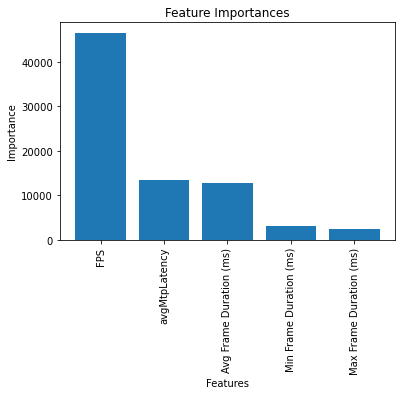

In [19]:
# Plot a bar chart of the sorted feature importances
plt.bar(sorted_features, sorted_importances)
plt.title("Feature Importances")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=90)
plt.show()